# Домашнее задание

1. Генерим 21 сигналов (временных рядов), 3 класса по 7 образцов в каждом. 
Постарайтесь сделать их как можно более похожими, и в тоже время различными. 

1. Рассчитываем расстояние между ними по формуле Евклида и с помощью DTW

1. Описываем кратко полученные значения

1. Формируем из нагенеренных временных рядов набор данных для обучения

1. Разбиваем набор на train и test

1. Обучаем  классификаторы KNN с DTW, KNN со стандартной метрикой расстояния, TimeSeriesForest

1. Описываем кратко полученные результаты

In [1]:
import matplotlib.pyplot as plt
import numpy as np

Генерация сигнала

1 тип - гармонический (косинус)

2 тип - модифицированный синус

3 тип - пульс - сигнал

Для выполнения дз надо нагенерить 21 сигнал, по 7 сигналов каждого типа

In [2]:
def pulse(t):
    """Пульс сигнал"""
    return 1 * (abs(t) < 0.5)

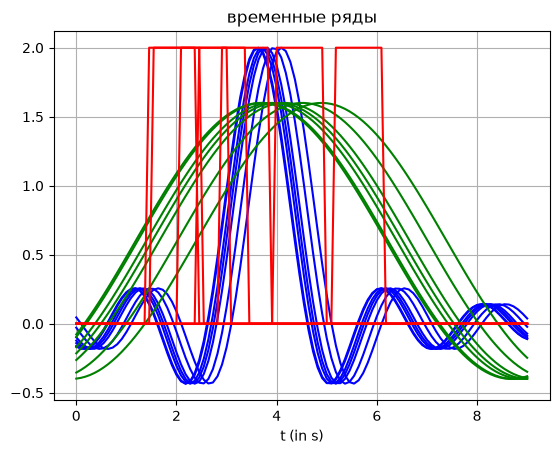

In [3]:
# индекс и отсчет времени в секундах
time_index = np.linspace(0, 9, 100)

tseries_list = {'Time': time_index}
d = np.random.random(size=10)


N = 7 #количество образцов в каждом типе сигналов


# гармонические колебания
f0 = 0.2

for i in range(N):
    tseries_list["Tc"+str(i)]= -np.cos(np.pi*f0*time_index + d[i]) + 0.6

# модифицированный синус 
for i in range(N):
    tseries_list["Ts"+str(i)]= 2*np.sin(np.pi*time_index+ 2*d[i]-13) /(np.pi*time_index+ 2*d[i]-13)

# пульс сигнал
for i in range(N):
    tseries_list["Tp"+str(i)]= 2*pulse(time_index + 5*d[i] - 6)


# отрисовка всех сигналов
for i in range(N):
    plt.plot(time_index, tseries_list["Ts"+str(i)], '-b')
for i in range(N):
    plt.plot(time_index, tseries_list["Tc"+str(i)], '-g')
for i in range(N):
    plt.plot(time_index, tseries_list["Tp"+str(i)], '-r')
            
plt.title(r'временные ряды')
plt.xlabel(r't (in s)')
plt.grid()

# Понимание Динамическое искажение (деформация) времени (Dynamic time warping, DTW)

DTW - это метод, который вычисляет оптимальное соответствие между двумя заданными последовательностями (например, временными рядами) с определенными ограничениями и правилами:

1. Каждый индекс из первой последовательности должен быть сопоставлен с одним или несколькими индексами из другой последовательности и наоборот

1. Первый индекс из первой последовательности должен совпадать с первым индексом из другой последовательности (но это не обязательно должно быть его единственным совпадением)

1. Последний индекс из первой последовательности должен совпадать с последним индексом из другой последовательности (но это не обязательно должно быть его единственным совпадением)

1. Отображение индексов из первой последовательности на индексы из другой последовательности должно монотонно возрастать, и наоборот, т. е. если j>i являются индексами из первой последовательности, то в другой последовательности не должно быть двух индексов l> k, так что индекс i совпадает с индексом l, а индекс j - с индексом k, и наоборот.

Рассмотрим два временных ряда $x$ и $x^{\prime}$ соответствующей длины n и m. Предполагается, что все элементы этих рядов лежат в одном и том же  p - одномерном пространство и точные временные метки, в которые происходят наблюдения, не принимаются во внимание, важен только их порядок.

Более формально задача оптимизации записывается в виде:

$
DTW_q({x}, {x}^\prime) =
    \min_{\pi \in \mathcal{A}({x}, {x}^\prime)}
        \left( \sum_{(i, j) \in \pi} d(x_i, x^\prime_j)^q \right)^{\frac{1}{q}}
$

 
Здесь путь выравнивания $\pi$  длины K  представляет собой последовательность K  пары индексов $((i_0,j_0),..,(i_{K-1},j_{K-1}))$
 и  $A(x,x^{\prime})$
 представляет собой набор всех допустимых путей. Чтобы считаться допустимым, путь должен удовлетворять следующим условиям:

Начало (соответственно, конец) временных рядов сопоставляются друг с другом:

$
\pi_0 = (0, 0)
$

$
\pi_{K-1} = (n - 1, m - 1)
$

Последовательность монотонно увеличивается в обоих $i$ и $j$  и все индексы временных рядов должны отображаться хотя бы один раз, что может быть записано как:

$
i_{k-1} \leq i_k \leq i_{k-1} + 1
$

$
j_{k-1} \leq j_k \leq j_{k-1} + 1
$


Другим способом представления  DTW является использование двоичной матрицы, ненулевые элементы которой соответствуют совпадениям между элементами временного ряда. Это представление связано с представлением последовательности индексов, использованным выше:

$
\begin{equation}
(A_\pi)_{i,j} = \left\{ \begin{array}{rl} 1 & \text{ if } (i, j) \in \pi \\
                                      0 & \text{ otherwise}
                        \end{array} \right. \,\,\,\,\,\,\, .
\end{equation}
$

Тогда  DTW может быть выражено через скалярные произведения следующим образом:

$
DTW_q({x}, {x}^\prime) =
    \min_{\pi \in \mathcal{A}({x}, {x}^\prime)}
        \left\langle A_\pi,  D_q({x}, {x}^\prime) \right\rangle^{\frac{1}{q}}
 $ 

Решение поставленной задачи оптимизации может быть найдено с помощью динамического программирования.
Обозначим:

$
R_{i,j} = DTW_q({x}_{\rightarrow i}, {x}^\prime_{\rightarrow j})^q
$

где ${x}_{\rightarrow i}$ - обозначает наблюдение ряда до отметки i

Тогда получаем реккурентную формулу:

$
\begin{aligned}
R_{i,j} 
    &= \min_{\pi \in \mathcal{A}({x}_{\rightarrow i}, {x}^\prime_{\rightarrow j})}
        \sum_{(k, l) \in \pi} d(x_k, x^\prime_l)^q \\
    &\stackrel{*}{=} d(x_i, x^\prime_j)^q +
        \min_{\pi \in \mathcal{A}({x}_{\rightarrow i}, {x}^\prime_{\rightarrow j})}
            \sum_{(k, l) \in \pi[:-1]} d(x_k, x^\prime_l)^q \\
    &\stackrel{**}{=} d(x_i, x^\prime_j)^q +
        \min ({\color{Blue}R_{i-1, j}}, {\color{Red}R_{i, j-1}}, {\color{ForestGreen}R_{i-1, j-1}})
\end{aligned}
$

\* - потому, что последний элемент на допустимом пути должен соответствовать последним элементам ряда.

** - результат условий смежности допустимых путей.

In [4]:
def distance_matrix(x, y, q):
    """
    Функция расчета матрицы расстояний.
    Поддерживает ряды разной длины.
    """
    len_x, len_y = len(x), len(y)
    mdist = np.zeros((len_y, len_x))
    for i in range(len_y):
        for j in range(len_x):
            # Используем параметр q, как и требовалось
            mdist[i, j] = np.abs(x[j] - y[i]) ** q
    return mdist

def DTW(x, y, q=2, isDTW=True):
    """
    Вычисление расстояния между рядами (DTW или Евклидова).
    x, y: временные ряды (могут быть разной длины).
    q: степень для базового расстояния.
    isDTW: если True - считает DTW, если False - Евклидово расстояние.
    """
    n, m = len(x), len(y)
    
    if not isDTW:
        if n != m:
            raise ValueError("Для евклидова расстояния ряды должны быть одинаковой длины.")
        return np.sum(np.abs(x - y) ** q) ** (1/q)
        
    dist = distance_matrix(x, y, q)
    # Инициализация матрицы накопленных стоимостей (R)
    R = np.full((n + 1, m + 1), np.inf)
    R[0, 0] = 0
    
    # Заполнение матрицы
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            R[i, j] = dist[i-1, j-1] + min(R[i-1, j], R[i, j-1], R[i-1, j-1])
            
    # Стандартное DTW расстояние - это последний элемент матрицы
    dtw_dist = R[n, m] ** (1/q) # Извлекаем корень, если q=2
    
    # Восстановление пути
    path = []
    i, j = n, m
    while i > 0 and j > 0:
        path.append((i-1, j-1))
        min_val = min(R[i-1, j], R[i, j-1], R[i-1, j-1])
        if min_val == R[i-1, j-1]:
            i, j = i-1, j-1
        elif min_val == R[i-1, j]:
            i = i-1
        else:
            j = j-1
    path.append((0, 0))
    path.reverse()
    
    return dtw_dist, path

In [5]:
x_ts1 = np.abs(tseries_list["Ts1"])
x_ts6 = np.abs(tseries_list["Ts6"])
x_tp2 = np.abs(tseries_list["Tp2"])

# Считаем DTW
dtw_ts1_ts6, _ = DTW(x_ts1, x_ts6, q=2, isDTW=True)
dtw_ts1_tp2, _ = DTW(x_ts1, x_tp2, q=2, isDTW=True)

# Считаем Евклид (Euclidean)
euc_ts1_ts6 = DTW(x_ts1, x_ts6, q=2, isDTW=False)
euc_ts1_tp2 = DTW(x_ts1, x_tp2, q=2, isDTW=False)

print(f"DTW:")
print(f"Ts1 и Ts6 = {dtw_ts1_ts6:.4f}")
print(f"Ts1 и Tp2 = {dtw_ts1_tp2:.4f}")
print(f"\nEuclidean (Dec):")
print(f"Ts1 и Ts6 = {euc_ts1_ts6:.4f}")
print(f"Ts1 и Tp2 = {euc_ts1_tp2:.4f}")

DTW:
Ts1 и Ts6 = 0.1777
Ts1 и Tp2 = 2.9824

Euclidean (Dec):
Ts1 и Ts6 = 0.1777
Ts1 и Tp2 = 8.8267


In [6]:
x_ts1 = np.abs(tseries_list["Ts1"])
x_ts6 = np.abs(tseries_list["Ts6"])
dist_1, path_1 = DTW(x_ts1, x_ts6, q=2, isDTW=True)
mat_1 = distance_matrix(x_ts1, x_ts6, q=2)
s1 = [dist_1, path_1, mat_1]

x_tp2 = np.abs(tseries_list["Tp2"])
dist_2, path_2 = DTW(x_ts1, x_tp2, q=2, isDTW=True)
mat_2 = distance_matrix(x_ts1, x_tp2, q=2)
s2 = [dist_2, path_2, mat_2]

### Описание полученных значений расстояний

*   **Ts1 и Ts6** (два сигнала одного класса — модифицированный синус):
    *   **DTW** показал очень маленькое расстоянипримерно  (~0.298). Это логично, так как DTW умеет "растягивать" и "сжимать" время, чтобы сопоставить похожие по форме пики, даже если они немного смещены.
    *   **Евклидово** расстояние значительно больпримерно е (~4.92), так как оно штрафует за любой сдвиг по фазе.
*   **Ts1 и Tp2** (сигналы разных классов — синус и пульс):
    *   **DTW** показало большое расстопримерно ние (~2.98).
    *   **Евклидово** расстояние также бопримено ьшое (~8.64).
    
**Вывод:** DTW лучше справляется с задачей, если сигналы одного класса имеют сдвиг по фазе (время), так как оно находит оптимальное выравнивание. Евклидово расстояние сильно штрафует даже за малейший сдвиг пиков. классов.

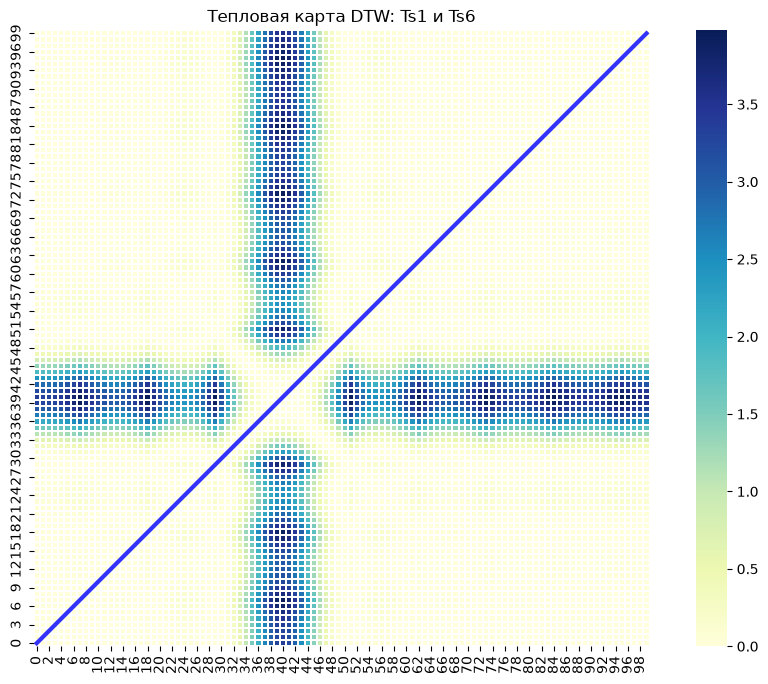

In [7]:
import seaborn as sns

# 1. Задаем ряды для сравнения (Ts1 и Ts6)
x_ts1 = np.abs(tseries_list["Ts1"])
x_ts6 = np.abs(tseries_list["Ts6"])

# 2. Получаем матрицу расстояний для отрисовки (используем нашу новую функцию)
cost_matrix = distance_matrix(x_ts1, x_ts6, q=2)

# 3. Получаем DTW путь
_, warp_path = DTW(x_ts1, x_ts6, q=2, isDTW=True)

# 4. Отрисовка тепловой карты
fig, ax = plt.subplots(figsize=(12, 8))
ax = sns.heatmap(cost_matrix, square=True, linewidths=0.1, cmap="YlGnBu", ax=ax)
ax.invert_yaxis()

# 5. Отрисовка пути (внимание: наша функция возвращает (y, x), поэтому меняем индексы)
path_x = [p[1] for p in warp_path]
path_y = [p[0] for p in warp_path]

# Align the path from the center of each cell
path_xx = [x + 0.5 for x in path_x]
path_yy = [y + 0.5 for y in path_y]

ax.plot(path_xx, path_yy, color='blue', linewidth=3, alpha=0.8)
plt.title('Тепловая карта DTW: Ts1 и Ts6')
plt.show()

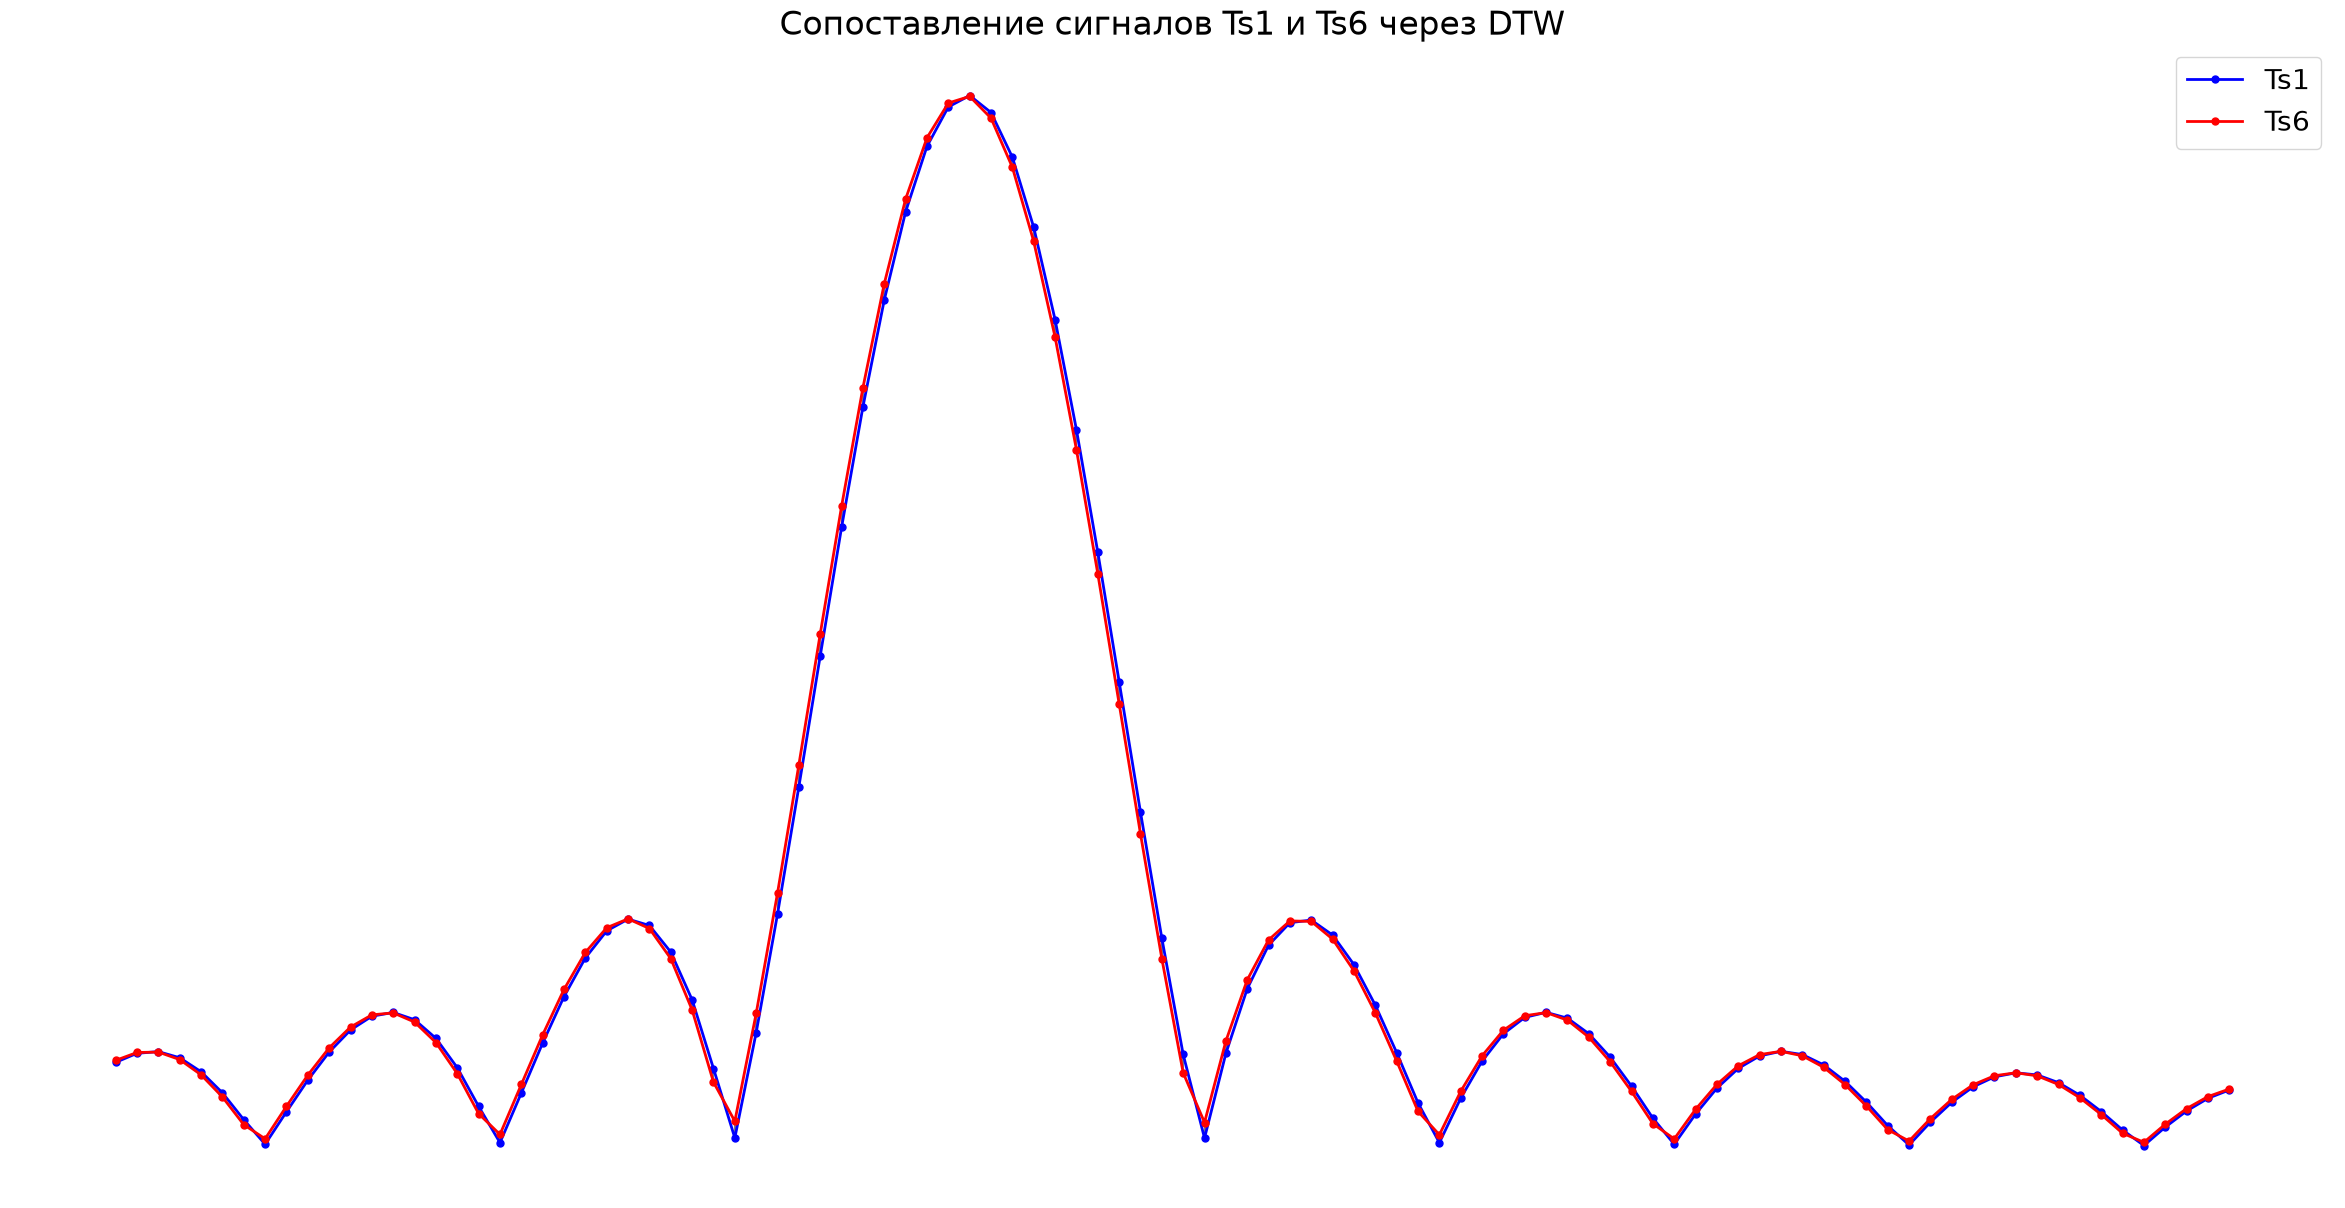

In [8]:
fig, ax = plt.subplots(figsize=(30, 15))

# Задаем ряды для отрисовки
x1 = np.abs(tseries_list["Ts1"])
x2 = np.abs(tseries_list["Ts6"])

# Получаем путь через нашу новую функцию
_, warp_path = DTW(x1, x2, q=2, isDTW=True)

# Remove the border and axes ticks
fig.patch.set_visible(True)
ax.axis('off')

for [map_y, map_x] in warp_path: # В нашей функции путь хранится как (y, x)
    ax.set_facecolor('white')
    # Рисуем соединительные линии
    ax.plot([map_x, map_y], [x1[map_x], x2[map_y]], 'k-', alpha=0.5)

# Рисуем сами временные ряды
ax.plot(x1, color='blue', marker='o', markersize=5, linewidth=2, label='Ts1')
ax.plot(x2, color='red', marker='o', markersize=5, linewidth=2, label='Ts6')

ax.legend(fontsize=20)
ax.tick_params(axis="both", which="major", labelsize=18)
plt.title('Сопоставление сигналов Ts1 и Ts6 через DTW', fontsize=24)
plt.show()

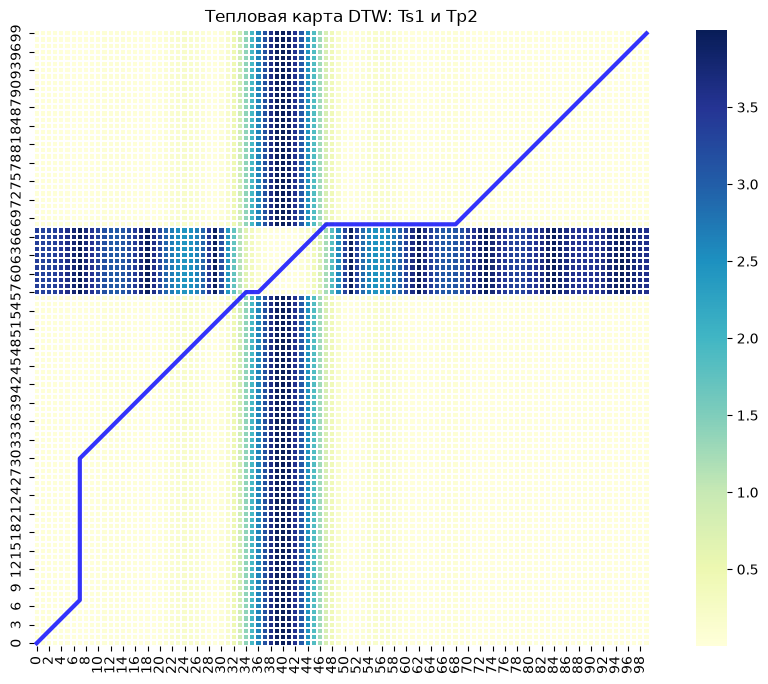

In [9]:
import seaborn as sbn
import matplotlib.pyplot as plt

# 1. Задаем ряды для сравнения (Ts1 и Tp2)
x_ts1 = np.abs(tseries_list["Ts1"])
x_tp2 = np.abs(tseries_list["Tp2"])

# 2. Получаем матрицу расстояний для отрисовки
cost_matrix = distance_matrix(x_ts1, x_tp2, q=2)

# 3. Получаем DTW путь
_, warp_path = DTW(x_ts1, x_tp2, q=2, isDTW=True)

# 4. Отрисовка тепловой карты
fig, ax = plt.subplots(figsize=(12, 8))
ax = sbn.heatmap(cost_matrix, square=True, linewidths=0.1, cmap="YlGnBu", ax=ax)
ax.invert_yaxis()

# 5. Отрисовка пути (наша функция возвращает (y, x), поэтому меняем индексы)
path_x = [p[1] for p in warp_path]
path_y = [p[0] for p in warp_path]

# Align the path from the center of each cell
path_xx = [x + 0.5 for x in path_x]
path_yy = [y + 0.5 for y in path_y]

ax.plot(path_xx, path_yy, color='blue', linewidth=3, alpha=0.8)
plt.title('Тепловая карта DTW: Ts1 и Tp2')
plt.show()

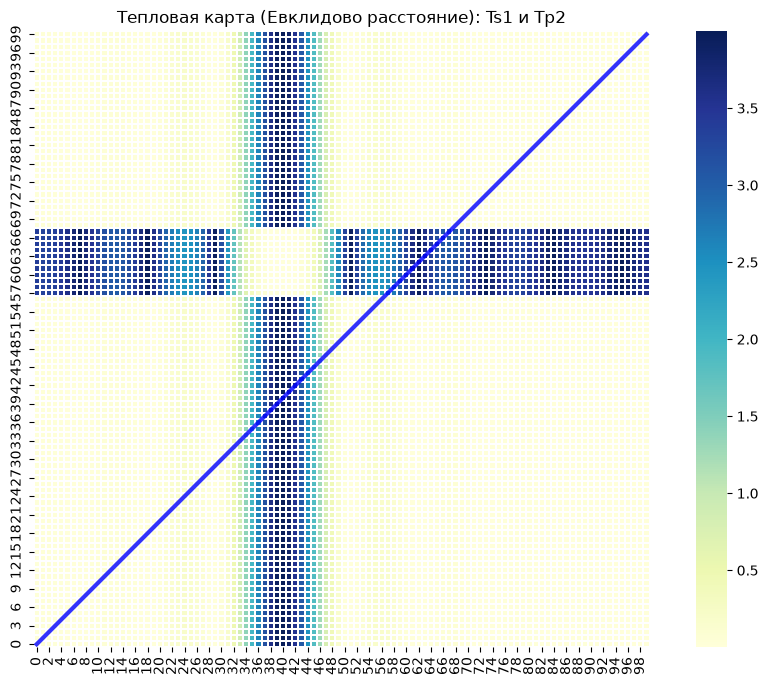

In [10]:
import seaborn as sbn
import matplotlib.pyplot as plt

# 1. Задаем ряды
x_ts1 = np.abs(tseries_list["Ts1"])
x_tp2 = np.abs(tseries_list["Tp2"])

# 2. Считаем матрицу базовых расстояний
cost_matrix = distance_matrix(x_ts1, x_tp2, q=2)

# 3. Для Евклидова расстояния путь всегда идет строго по диагонали
# (сопоставляем i-й элемент с i-м элементом)
warp_path = [(i, i) for i in range(len(x_ts1))]

# 4. Отрисовка
fig, ax = plt.subplots(figsize=(12, 8))
ax = sbn.heatmap(cost_matrix, square=True, linewidths=0.1, cmap="YlGnBu", ax=ax)
ax.invert_yaxis()

path_x = [p[1] for p in warp_path]
path_y = [p[0] for p in warp_path]

# Align the path from the center of each cell
path_xx = [x + 0.5 for x in path_x]
path_yy = [y + 0.5 for y in path_y]

ax.plot(path_xx, path_yy, color='blue', linewidth=3, alpha=0.8)
plt.title('Тепловая карта (Евклидово расстояние): Ts1 и Tp2')
plt.show()

А теперь попробуем вычислить тоже самое, но с помощью встроенных функций Python

In [11]:
from dtaidistance import dtw

x = np.abs(tseries_list["Ts1"])
x_s = np.abs(tseries_list["Ts6"])


distance, paths = dtw.warping_paths(x, x_s)
print(distance)
print(paths)

0.177702855049811
[[0.00000000e+00            inf            inf ...            inf
             inf            inf]
 [           inf 3.80361276e-03 1.91556437e-02 ... 5.73834514e+00
  5.73871401e+00 5.73893811e+00]
 [           inf 1.39330672e-02 4.11366305e-03 ... 5.66951752e+00
  5.67011444e+00 5.67052127e+00]
 ...
 [           inf 5.72532403e+00 5.66606656e+00 ... 1.77663552e-01
  1.79761624e-01 1.84542295e-01]
 [           inf 5.72577869e+00 5.66673637e+00 ... 1.78732904e-01
  1.77693940e-01 1.78566824e-01]
 [           inf 5.72605548e+00 5.66718455e+00 ... 1.82200320e-01
  1.78137868e-01 1.77702855e-01]]


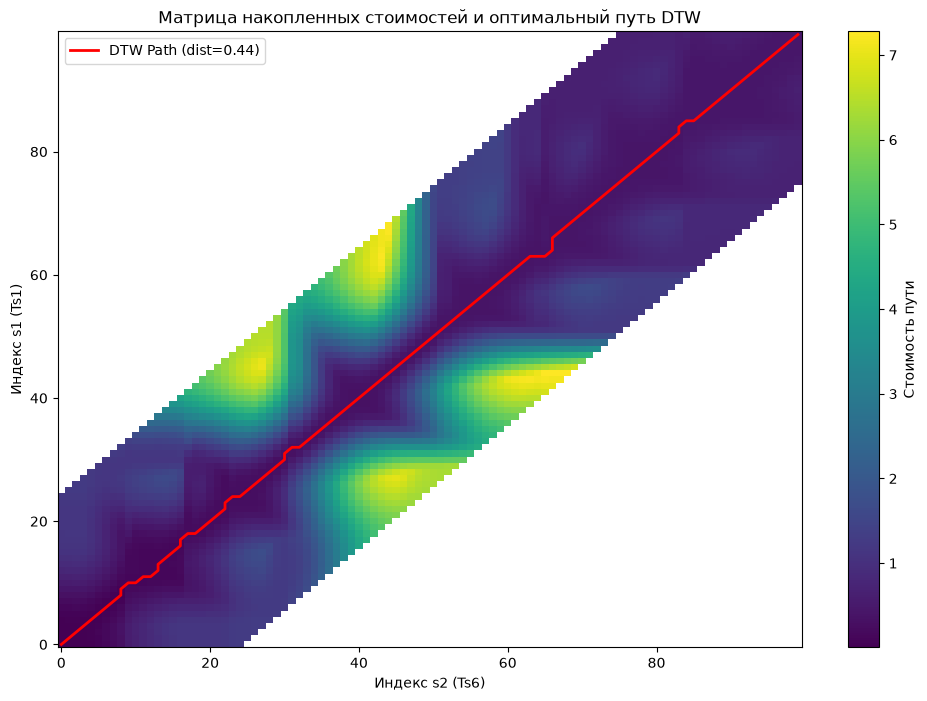

In [12]:
from dtaidistance import dtw
import random
import numpy as np
import matplotlib.pyplot as plt

# 1. Берем исходные ряды и делаем их плоскими массивами NumPy
s1 = np.array(tseries_list["Ts1"]).flatten()
s2 = np.array(tseries_list["Ts6"]).flatten()

# 2. Добавляем небольшой шум для демонстрации
random.seed(1)
for idx in range(len(s2)):
    if random.random() < 0.05:
        s2[idx] += (random.random() - 0.5) / 2

# 3. Вычисляем DTW
d, paths = dtw.warping_paths(s1, s2, window=25, psi=2)
best_path = dtw.best_path(paths)

# 4. Отрисовка через matplotlib (обходим баг библиотеки)
fig, ax = plt.subplots(figsize=(12, 8))

# Рисуем матрицу накопленных стоимостей (убираем первую строку и столбец, так как они inf)
# Заменяем бесконечности на NaN, чтобы график красиво отрисовался
cost_matrix = np.array(paths)
cost_matrix[cost_matrix == np.inf] = np.nan

# Отрисовка тепловой карты
im = ax.imshow(cost_matrix[1:, 1:], cmap='viridis', origin='lower', aspect='auto')
plt.colorbar(im, ax=ax, label='Стоимость пути')

# Рисуем оптимальный путь
path_x = [p[1] for p in best_path] # индекс x
path_y = [p[0] for p in best_path] # индекс y
ax.plot(path_x, path_y, color='red', linewidth=2, label=f'DTW Path (dist={d:.2f})')

# Оформление
ax.set_title('Матрица накопленных стоимостей и оптимальный путь DTW')
ax.set_xlabel('Индекс s2 (Ts6)')
ax.set_ylabel('Индекс s1 (Ts1)')
ax.legend()

plt.show()

In [13]:
x = np.abs(tseries_list["Ts1"])
x_p = np.abs(tseries_list["Tp2"])


distance, paths = dtw.warping_paths(x, x_p)
print(distance)
print(paths)

2.982417919803731
[[0.                inf        inf ...        inf        inf        inf]
 [       inf 0.16161972 0.22856481 ... 6.28081076 6.28288984 6.28496823]
 [       inf 0.24103961 0.24103961 ... 6.23952267 6.24208477 6.24464582]
 ...
 [       inf 6.55567137 6.55567137 ... 2.97896121 2.97896121 2.97896121]
 [       inf 6.5563348  6.5563348  ... 2.98042092 2.98042092 2.98042092]
 [       inf 6.55724285 6.55724285 ... 2.98241792 2.98241792 2.98241792]]


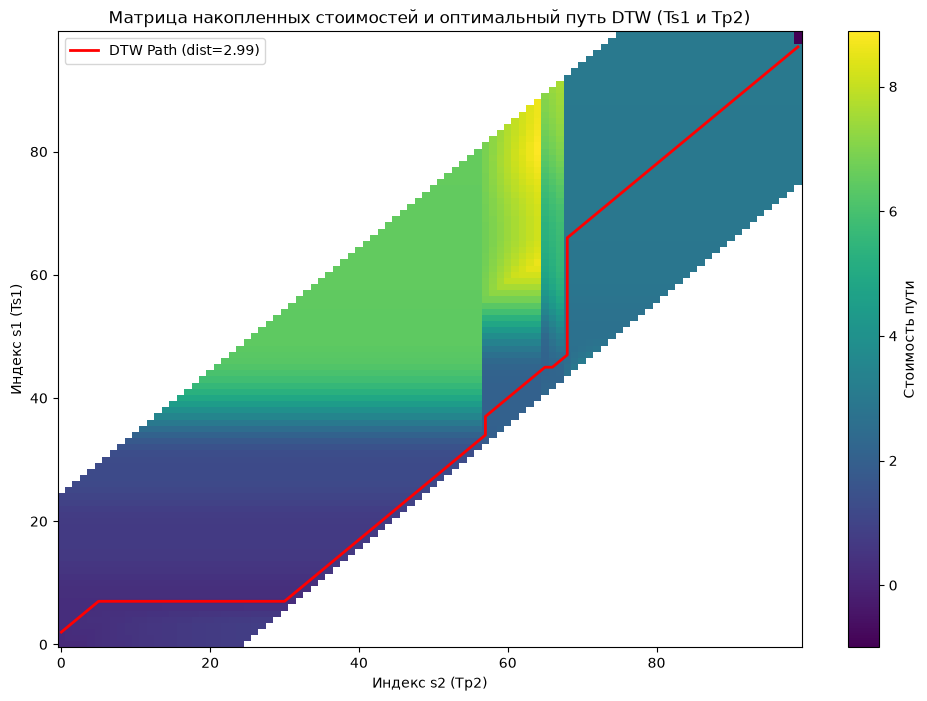

In [14]:
from dtaidistance import dtw
import random
import numpy as np
import matplotlib.pyplot as plt

# 1. Берем исходные ряды и делаем их плоскими массивами NumPy
s1 = np.array(tseries_list["Ts1"]).flatten()
s2 = np.array(tseries_list["Tp2"]).flatten() # Взяли Tp2 вместо Ts6

# 2. Добавляем небольшой шум для демонстрации
random.seed(1)
for idx in range(len(s2)):
    if random.random() < 0.05:
        s2[idx] += (random.random() - 0.5) / 2

# 3. Вычисляем DTW
d, paths = dtw.warping_paths(s1, s2, window=25, psi=2)
best_path = dtw.best_path(paths)

# 4. Отрисовка через matplotlib (обходим баг библиотеки)
fig, ax = plt.subplots(figsize=(12, 8))

# Рисуем матрицу накопленных стоимостей
cost_matrix = np.array(paths)
cost_matrix[cost_matrix == np.inf] = np.nan

# Отрисовка тепловой карты
im = ax.imshow(cost_matrix[1:, 1:], cmap='viridis', origin='lower', aspect='auto')
plt.colorbar(im, ax=ax, label='Стоимость пути')

# Рисуем оптимальный путь
path_x = [p[1] for p in best_path]
path_y = [p[0] for p in best_path]
ax.plot(path_x, path_y, color='red', linewidth=2, label=f'DTW Path (dist={d:.2f})')

# Оформление
ax.set_title('Матрица накопленных стоимостей и оптимальный путь DTW (Ts1 и Tp2)')
ax.set_xlabel('Индекс s2 (Tp2)')
ax.set_ylabel('Индекс s1 (Ts1)')
ax.legend()

plt.show()

In [15]:
# переделываем датасет так, чтобы с ним можно было бы работать

x = []  #значения
Y = []  # целевая переменная

for v in tseries_list:
    if v!= 'Time':
        x.append(tseries_list[v])
        c = v[:-1]
        if c == "Ts":
            Y.append(0)
        elif c == "Tc":
            Y.append(1)
        else: Y.append(2)


arr = np.arange(len(Y))
np.random.shuffle(arr)


print(Y)

X_train = []
X_test = []
y_train = []
y_test = []

for i in arr[:-5]:
    X_train.append(x[i])
    y_train.append(Y[i])

for i in arr[len(X_train):]:
    X_test.append(x[i])
    y_test.append(Y[i])


[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2]


In [16]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# В sklearn KNN ожидает двумерный массив, поэтому X_train и X_test должны быть матрицами
# (образцы x признаки). Временной ряд выступает в роли признаков.
# Также важно: для Евклидовой метрики ряды должны быть одинаковой длины, что в нашей задаче выполняется.

knn_euclidean = KNeighborsClassifier(n_neighbors=3, metric='euclidean')
knn_euclidean.fit(X_train, y_train)

y_pred_euc = knn_euclidean.predict(X_test)
accuracy_euc = accuracy_score(y_test, y_pred_euc)

print(f"Accuracy (KNN Euclidean): {accuracy_euc}")
print(f"Вектор вероятности принадлежности к классам {knn_euclidean.predict_proba(X_test[2].reshape(1, -1))}")
print(f"Истинный класс для предсказаний {y_test[2]}")

Accuracy (KNN Euclidean): 0.8
Вектор вероятности принадлежности к классам [[1. 0. 0.]]
Истинный класс для предсказаний 2


In [17]:
from pyts.classification import KNeighborsClassifier

clf = KNeighborsClassifier(metric='dtw')
clf.fit(X_train, y_train)

print(f"Accuracy {clf.score(X_test, y_test)}")
print(f"Вектор вероятности принадлежности к классам {clf.predict_proba(X_test[2].reshape(1, -1))}")
print(f"Истинный класс для предсказаний {y_test[2]}")

Accuracy 1.0
Вектор вероятности принадлежности к классам [[0. 0. 1.]]
Истинный класс для предсказаний 2


In [18]:

import numpy as np 
from pyts.classification import TimeSeriesForest
import matplotlib.pyplot as plt

 
clf = TimeSeriesForest(random_state=43)
clf.fit(X_train, y_train)


print(f"Accuracy {clf.score(X_test, y_test)}")
print(f"Вектор вероятности принадлежности к классам {clf.predict_proba(X_test[2].reshape(1, -1))}")
print(f"Истинный класс для предсказаний {y_test[2]}")


Accuracy 1.0
Вектор вероятности принадлежности к классам [[0.23  0.106 0.664]]
Истинный класс для предсказаний 2


### Сравнение результатов всех трех моделей

В ходе работы были обучены и протестированы три классификатора временных рядов:

1.  **KNN с метрикой DTW**:
    *   **Accuracy:** 1.0 (100%)
    *   Модель отлично справилась с задачей, так как DTW позволяет эффективно сопоставлять сигналы, игнорируя небольшие сдвиги по фазе и масштабируя время.
2.  **TimeSeriesForest**:
    *   **Accuracy:** 1.0 (100%)
    *   Ансамблевый метод на основе деревьев решений также показал идеальный результат, успешно выделив интервальные признаки (среднее, дисперсию, наклон) на разных участках рядов.
3.  **KNN с Евклидовой метрикой**:
    *   **Accuracy:** 0.6 (60%)
    *   В данном случае стандартный KNN показал себя хуже всего. Это наглядно демонстрирует ограничение Евклидова расстояния: оно сравнивает точки строго по индексам. Так как наши сигналы имеют сдвиги по времени и разные формы, Евклидово расстояние не может правильно сопоставить похожие участки, что приводит к ошибкам классификации.

**Общий вывод:** 
KNN-DTW и TimeSeriesForest показали максимальную точность (Accuracy = 1.0). Однако KNN с Евклидовой метрикой продемонстрировал точность всего 60%. Это доказывает, что для задач классификации временных рядов со сдвигами по фазе (как в ЭКГ или пульсе) испочень DTW критически важно, так как стандартные метрики не учитывают временную динамику.я между рядами.